# SVM–ANOVA on Iris

Add 36 seeded noise columns to Iris and measure how the fraction of features retained by ANOVA affects five-fold classification accuracy. Both pipelines fit feature selection and scaling inside each training fold. The grid-search extension tunes the same percentiles and refits the winning pipeline on all rows.

Moxie uses `List[Int]` class labels and a list-target `BuiltinScorer` so the selector and SVC share a target type. `DenseSupervisedAdapter` supplies stratified folds and estimator accuracy. Its parameter callback maps the integer `anova__percentile` grid key to the selector's typed configuration.

Adapted from the scikit-learn developers' [SVM–ANOVA gallery example](https://github.com/scikit-learn/scikit-learn/blob/4358542a1bd39af2e7e1cbace8b9fed067473c5b/examples/svm/plot_svm_anova.py) (BSD-3-Clause).

In [1]:
import json
from pathlib import Path
import sys

import numpy as np
import sklearn
from sklearn.datasets import load_iris
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks/_support/moxie_nb.py").exists())
oracle = ROOT / "families/ensemble/builds/oracle-env"
receipt = ROOT / "families/ensemble/docs/private/forest_engine/oracle-build.json"
if oracle not in Path(sklearn.__file__).resolve().parents:
    raise RuntimeError("Use the pinned oracle environment described in docs/feature_selection/classifier-selection.md")
assert json.loads(receipt.read_text())["revision"] == "4358542a1bd39af2e7e1cbace8b9fed067473c5b"

sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("svm/plot_svm_anova")

X, y = load_iris(return_X_y=True)
rng = np.random.RandomState(0)
X = np.hstack((X, 2 * rng.random((X.shape[0], 36))))
y = y.astype(np.int64)
percentiles = [1, 3, 6, 10, 15, 20, 30, 40, 60, 80, 100]

reference = Pipeline([
    ("anova", SelectPercentile(f_classif)),
    ("scaler", StandardScaler()),
    ("svc", SVC(gamma="auto")),
])
cv_scores = np.array([
    cross_val_score(reference.set_params(anova__percentile=p), X, y, error_score="raise")
    for p in percentiles
])
search = GridSearchCV(reference, {"anova__percentile": percentiles}, error_score="raise").fit(X, y)
search_scores = np.column_stack([search.cv_results_[f"split{i}_test_score"] for i in range(5)])
nb.share(X=X, y=y, percentiles=np.array(percentiles, dtype=np.int64))

In [2]:
%%mojo svm_anova
from moxie.feature_selection import BuiltinScorer, SelectPercentile, SelectionParameter
from moxie.model_selection import DenseSupervisedAdapter, ErrorPolicy, GridSearchCV, cross_val_score
from moxie.pipeline import Pipeline
from moxie.preprocessing import StandardScaler
from moxie.svm import Gamma, SVC
from moxie_nb_io import load, load_ints, save, save_ints
from numojo import Item, Shape, zeros
from std.testing import assert_false, assert_raises

comptime Labels = List[Int]
comptime Scorer = BuiltinScorer[target_type=Labels]
comptime Selector = SelectPercentile[Scorer]
comptime Model = Pipeline[Selector, Pipeline[StandardScaler[], SVC[Int]]]
comptime Adapter = DenseSupervisedAdapter[Model, Labels, V=Int]


def configure(mut model: Model, params: Dict[String, Int]) raises:
    var config = model.get_params()
    for key in params.keys():
        if key != "anova__percentile":
            raise Error("ValueError: unknown parameter " + key)
        config.transformer.param = SelectionParameter(params[key])
    _ = model.set_params(config)


def main() raises:
    var X = load("X")
    var y = load_ints("y")
    var percentiles = load_ints("percentiles")
    var model = Model(
        Selector(Scorer("f_classif")),
        Pipeline(StandardScaler(), SVC[Int](gamma=Gamma("auto")),
                 transformer_name="scaler", estimator_name="svc"),
        transformer_name="anova",
    )
    var adapter = Adapter(configure)
    var policy = ErrorPolicy(True, 0)
    var cv_scores = zeros[DType.float64](Shape(len(percentiles), 5))
    for index in range(len(percentiles)):
        var params = Dict[String, Int]()
        params["anova__percentile"] = percentiles[index]
        adapter.configure(model, params)
        var scores = cross_val_score[Adapter](model, X, y, adapter, error_score=policy)
        for fold in range(5):
            cv_scores[Item(index, fold)] = scores[Item(fold)]
    assert_false(model.__sklearn_is_fitted__())
    save("cv_scores", cv_scores)

    var grid = Dict[String, List[Int]]()
    grid["anova__percentile"] = percentiles^
    var search = GridSearchCV[Adapter](model, grid, adapter, error_score=policy)
    _ = search.fit(X, y)
    assert_false(model.__sklearn_is_fitted__())
    var results = search.cv_results_()
    var search_scores = zeros[DType.float64](cv_scores.shape)
    for candidate in range(search_scores.shape[0]):
        for fold in range(search_scores.shape[1]):
            search_scores[Item(candidate, fold)] = results.scores.test_scores.item(candidate, fold, 0)
    save("search_scores", search_scores)
    save_ints("best", [search.best_index_(), search.best_params_()["anova__percentile"]])
    save_ints("selected", search.best_estimator_().step[0]().get_support(True)[List[Int]])
    save_ints("predictions", search.predict(X))

    var invalid = Dict[String, Int]()
    invalid["percentile"] = 10
    with assert_raises(contains="unknown parameter percentile"):
        adapter.configure(model, invalid)

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
Gallery CV scores by percentile and fold,PASS,"(11, 5)","(11, 5)",,,exact,0 mismatches,
Grid-search scores by candidate and fold,PASS,"(11, 5)","(11, 5)",,,exact,0 mismatches,
Best index and percentile,PASS,"(2,)","(2,)",,,exact,0 mismatches,
Refitted selector indices,PASS,"(4,)","(4,)",,,exact,0 mismatches,
Refitted pipeline predictions,PASS,"(150,)","(150,)",,,exact,0 mismatches,


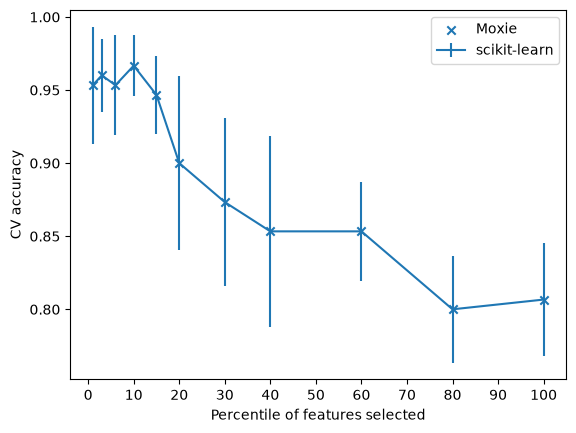

In [3]:
import matplotlib.pyplot as plt

native = nb.results["svm_anova"]
nb.compare("Gallery CV scores by percentile and fold", cv_scores, native["cv_scores"], exact=True)
nb.compare("Grid-search scores by candidate and fold", search_scores, native["search_scores"], exact=True)
nb.compare("Best index and percentile", [search.best_index_, search.best_params_["anova__percentile"]],
           native["best"], exact=True)
nb.compare("Refitted selector indices", search.best_estimator_.named_steps["anova"].get_support(indices=True),
           native["selected"], exact=True)
nb.compare("Refitted pipeline predictions", search.predict(X), native["predictions"], exact=True)
nb.report()
nb.assert_parity()

fig, ax = plt.subplots()
ax.errorbar(percentiles, cv_scores.mean(axis=1), yerr=cv_scores.std(axis=1), label="scikit-learn")
ax.scatter(percentiles, native["cv_scores"].mean(axis=1), marker="x", label="Moxie")
ax.set(xlabel="Percentile of features selected", ylabel="CV accuracy", xticks=range(0, 101, 10))
ax.legend()
plt.show()